# 7.3 Finding and Selecting the Right Model

**Module 7 · Note 3**

The Hub holds an enormous number of models, and the number grows every day. That is both the opportunity and the problem. Somewhere there is probably a model close to what you need, but there are also many that look right and aren't: trained for a slightly different task, too big for your hardware, unable to read inputs as long as yours, or advertised with numbers that won't hold on your data.

In Note 7.2 we learned what a model repository contains and how to read a model card. This note turns that knowledge into a method for choosing. We start from the problem rather than the model, map problems to the kinds of model that solve them, estimate whether a model will fit on your hardware *before* downloading it, and then read a model card critically, testing its claims rather than trusting them. Note 7.7 puts the whole method into practice on a real selection.

**Key question:** *Given a problem, how do we find a pretrained model that fits it, and how do we tell whether its advertised performance will hold for us?*

**By the end of this note you will be able to:**
- turn a problem into the questions that narrow down a model search;
- name the main task types on the Hub and recognise which one a problem belongs to;
- estimate a model's memory needs and input limit from its metadata, without downloading it;
- explain how input length drives compute, and when attention's quadratic cost starts to matter;
- check a model card's claims against your own measurements, and explain why a benchmark score may not transfer;
- weigh hosted APIs against running models locally.

**Before you start:** read Notes 7.1 and 7.2. You'll use the pipeline API (7.1), model cards and metadata (7.2), parameters × bytes (7.1, Section 6), and attention's cost growing with sequence length (Note 6.3).

### Setup

The usual imports, seeds and device check. The same harmless warnings as in the previous notes will appear (TqdmWarning, the unauthenticated-request message and, on a Mac, a few `W…` lines). This note downloads two more models than earlier notes, a small text generator and a sentence-embedding model, so its first run takes longer.

In [1]:
import time, hashlib
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset
from huggingface_hub import HfApi, ModelCard, get_safetensors_metadata
from transformers import pipeline, AutoConfig, AutoTokenizer, AutoModelForSequenceClassification

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1017 13:03:14.797000 73645 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 13:03:14.889000 73645 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 13:03:14.911000 73645 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: Matching Models to Problems

A common way to pick a model is to search for something popular and try it. Sometimes it works. More often it wastes an afternoon on a model that was never right for the job. A better habit is to describe the problem first, in a few concrete questions, and let the answers filter the search:

1. **What is the task?** What goes in and what must come out: a label for a whole text, a label for each word, a span copied from a passage, new text, a vector, a label for an image? This decides the *kind* of model (Section 2).
2. **What do the inputs look like?** Language, domain (tweets, legal contracts, film reviews), and above all *length*. A model that reads 512 tokens can't read a 20-page document in one go (Section 3).
3. **What hardware will run it, and how fast must it answer?** This sets an upper limit on model size (Section 3).
4. **How good must it be, measured how?** And on whose data? A benchmark number is evidence, not a guarantee (Section 4).
5. **Where will it run, and what are you allowed to do with it?** On your own machine or through someone else's service (Section 5), and under what licence (Note 7.2).

Only after these questions does it make sense to look at specific models. The questions turn "find a good model" into "find a model that does *this task*, on *inputs like these*, within *this budget*, *this well*, *under these terms*", which is far easier to answer.

> 🖼 *IMAGE 7.3.1 — From Problem to Shortlist.* A funnel diagram on a white background. At the top, a wide band labelled "All models on the Hub" filled with many small blue dots. The funnel narrows through five horizontal filter bars, each with an icon and a question: (1) a puzzle-piece icon, "Task: what goes in, what comes out?"; (2) a ruler icon, "Inputs: language, domain, length"; (3) a chip icon, "Hardware and speed: what will run it?"; (4) a target icon, "Quality: how good, measured on whose data?"; (5) a scales icon, "Deployment and licence: where, and is it allowed?". Fewer dots remain after each bar. At the bottom, three dots in a small box labelled "shortlist to test on your own data". Takeaway: describe the problem first; each answer removes most candidates before you download anything.

The first filter is the task itself, so that is where we start.

## 2. A Map of Common Tasks

Every model on the Hub is tagged with the task it was built for, its **pipeline tag**, and the Hub's search can filter by it. Here are seven well-known models, one per common task, with the tag the Hub gives each:

In [2]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
MINILM = "sentence-transformers/all-MiniLM-L6-v2"
GPT = "distilbert/distilgpt2"
task_examples = [SST2, "distilbert/distilbert-base-cased-distilled-squad", "sshleifer/distilbart-cnn-12-6",
                 GPT, MINILM, "google/vit-base-patch16-224", "openai/clip-vit-base-patch32"]
api = HfApi()
for r in task_examples:
    print(f"{api.model_info(r).pipeline_tag:<31} {r}")       # the task tag from the Hub, no download

text-classification             distilbert/distilbert-base-uncased-finetuned-sst-2-english


question-answering              distilbert/distilbert-base-cased-distilled-squad


summarization                   sshleifer/distilbart-cnn-12-6


text-generation                 distilbert/distilgpt2


sentence-similarity             sentence-transformers/all-MiniLM-L6-v2


image-classification            google/vit-base-patch16-224


zero-shot-image-classification  openai/clip-vit-base-patch32


These tags are the vocabulary of model search. What each means in practice:

| Task (pipeline tag) | Input → output | Typical use |
|---|---|---|
| `text-classification` | text → one label for the whole text | sentiment, spam, topic, intent |
| `question-answering` | question + passage → the span of the passage that answers it | searching manuals, FAQs, documents |
| `summarization` | long text → shorter text | news digests, meeting notes |
| `text-generation` | prompt → continuation | drafting, chat, code completion |
| `sentence-similarity` (also `feature-extraction`) | text → a vector of numbers | semantic search, clustering, duplicate detection |
| `image-classification` | image → one label from a fixed set | product photos, medical scans |
| `zero-shot-image-classification` | image + candidate labels in words → the best label | classifying into categories chosen at run time |

Notice how the same architecture serves different tasks. The first two models are both DistilBERT, one fine-tuned for classification and one for question answering. What makes them different is the head and the fine-tuning (Note 7.1, Section 4). Let's run three of these tasks with small models. Question answering and summarisation stay on the map only, to keep downloads down, and the image tasks get their turn in Note 7.5.

**Text classification**, which you already know:

In [3]:
classifier = pipeline("text-classification", model=SST2, device=device)
print(classifier("The soundtrack alone is worth the price of the ticket."))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 17060.69it/s]

[{'label': 'POSITIVE', 'score': 0.9995796084403992}]


**Text generation** with distilgpt2, a small version of GPT-2. With `do_sample=False`, the pipeline always picks the most likely next token: greedy decoding, from Note 6.6.

In [4]:
generator = pipeline("text-generation", model=GPT, device=device)    # downloads about 353 MB the first time
out = generator("The best thing about this movie is", max_new_tokens=20, do_sample=False)
print(out[0]["generated_text"])

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 8878.56it/s]

The best thing about this movie is that it's a very good movie. It's a very good movie. It's a very good


The model continues the prompt fluently but falls into a loop: "It's a very good movie" twice in 20 tokens. Greedy decoding often repeats like this, exactly as you saw with your own model in Note 6.6. Note 7.5 tries the sampling strategies that fix it.

**Embeddings** with all-MiniLM-L6-v2, a small model trained so that sentences with similar meanings get similar vectors. The pipeline returns one vector per token; averaging them gives one vector per sentence.

In [5]:
embedder = pipeline("feature-extraction", model=MINILM, device=device)
sentences = ["A thrilling, beautifully acted film.",
             "An exciting movie with superb performances.",
             "The parcel arrived on Tuesday."]
vectors = [torch.tensor(embedder(s)[0]).mean(dim=0) for s in sentences]   # (tokens, 384) -> (384,) per sentence
print("vector length:", vectors[0].shape[0])
for i, j in [(0, 1), (0, 2), (1, 2)]:
    print(f"cosine {F.cosine_similarity(vectors[i], vectors[j], dim=0):.3f}  {sentences[i]!r} vs {sentences[j]!r}")
del generator, embedder

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10536.91it/s]

vector length: 384
cosine 0.734  'A thrilling, beautifully acted film.' vs 'An exciting movie with superb performances.'
cosine -0.007  'A thrilling, beautifully acted film.' vs 'The parcel arrived on Tuesday.'
cosine 0.008  'An exciting movie with superb performances.' vs 'The parcel arrived on Tuesday.'


Each sentence becomes a vector of 384 numbers. The two film sentences share almost no words ("thrilling, beautifully acted film" against "exciting movie with superb performances"), yet their cosine similarity is 0.734, while each scores about zero against the sentence about a parcel (−0.007 and 0.008). The model compares meanings, not words, which is what makes semantic search possible. Note 7.5 builds a search engine on it.

> **Key terms**
> - **Pipeline tag (task tag):** the Hub's label for the task a model was built for, such as `text-classification`; it is also the name you pass to `pipeline(...)`.
> - **Greedy decoding:** generating text by always choosing the single most likely next token.
> - **Sentence embedding:** one vector representing a whole sentence, built so that similar meanings give nearby vectors.

> **Check yourself 1.** A support team wants to find past tickets that describe the same problem as a new ticket, even when worded differently. Which task tag would you search for, and why not `text-classification`?

Knowing the task narrows the search to a few kinds of model. Within a kind, the next filter is whether a model fits your hardware and your inputs.

## 3. Model Size, Context Length and Compute Requirements

### 3.1 Size and memory, before you download

You can find out how big a model is without downloading it. A `.safetensors` file begins with a short header that lists every tensor's name, shape and number type, and `huggingface_hub` can read just that header. Combined with each model's configuration (a few kilobytes), it tells us how many numbers a model stores and how long an input it accepts.

In [6]:
BYTES = {"F32": 4, "BF16": 2, "F16": 2, "I64": 8}               # bytes per stored number, by data type
ladder = [MINILM, "distilbert/distilbert-base-uncased", "google-bert/bert-base-uncased",
          "google-bert/bert-large-uncased", "Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-7B"]
sizes = {}
for r in ladder:
    meta = get_safetensors_metadata(r)                         # reads only the files' headers
    counts = meta.parameter_count                              # {data type: how many numbers}
    n = sum(counts.values())
    gb = sum(k * BYTES[d] for d, k in counts.items()) / 1e9
    ctx = AutoConfig.from_pretrained(r).max_position_embeddings   # longest input, in tokens
    sizes[r] = n
    print(f"{r:<40} {n:>14,} numbers | stored as {'+'.join(counts):<7} | {gb:7.2f} GB | context {ctx:>7,} tokens")

sentence-transformers/all-MiniLM-L6-v2       22,713,728 numbers | stored as I64+F32 |    0.09 GB | context     512 tokens


distilbert/distilbert-base-uncased           66,985,530 numbers | stored as F32     |    0.27 GB | context     512 tokens


google-bert/bert-base-uncased               110,106,428 numbers | stored as F32     |    0.44 GB | context     512 tokens


google-bert/bert-large-uncased              336,226,108 numbers | stored as F32     |    1.34 GB | context     512 tokens


Qwen/Qwen2.5-0.5B                           494,032,768 numbers | stored as BF16    |    0.99 GB | context  32,768 tokens


...

Parse safetensors files:  50%|█████     | 2/4 [00:01<00:01,  1.12it/s]

Parse safetensors files:  75%|███████▌  | 3/4 [00:01<00:00,  1.79it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:02<00:00,  2.52it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:02<00:00,  1.90it/s]

Qwen/Qwen2.5-7B                           7,615,616,512 numbers | stored as BF16    |   15.23 GB | context 131,072 tokens


That's a size ladder spanning several hundred times, from 22,713,728 stored numbers (MiniLM) to 7,615,616,512 (Qwen2.5-7B, a general-purpose language model).

Three things to read from this table:
- **"Stored as" matters.** The BERT models store 32-bit floats (`F32`, 4 bytes each). The Qwen models store `BF16` (bfloat16), a 16-bit format, 2 bytes each. So Qwen2.5-0.5B, with more numbers than BERT-large, takes less disk: 0.99 GB against 1.34 GB. MiniLM also stores a few integers (`I64`), which are position indexes rather than learned weights. (The header counts everything stored, so its total can differ slightly from the number of trainable parameters.)
- **Context length varies enormously.** All four BERT-style encoders accept at most 512 tokens. The Qwen models accept 32,768 and 131,072. For long documents, that alone can decide the choice.
- **Disk size predicts memory.** To run a model you must at least hold its weights in memory, so the file size is a lower bound on the memory you need. Running it needs more: activations, and for generation, the cache of past keys and values (Note 7.6).

Using the rule from Note 7.1, parameters × bytes per parameter, we can estimate the weight memory in different number formats:

In [7]:
for r in ladder:
    print(f"{r:<40} float32: {sizes[r] * 4 / 1e9:6.2f} GB | float16: {sizes[r] * 2 / 1e9:6.2f} GB")

sentence-transformers/all-MiniLM-L6-v2   float32:   0.09 GB | float16:   0.05 GB
distilbert/distilbert-base-uncased       float32:   0.27 GB | float16:   0.13 GB
google-bert/bert-base-uncased            float32:   0.44 GB | float16:   0.22 GB
google-bert/bert-large-uncased           float32:   1.34 GB | float16:   0.67 GB
Qwen/Qwen2.5-0.5B                        float32:   1.98 GB | float16:   0.99 GB
Qwen/Qwen2.5-7B                          float32:  30.46 GB | float16:  15.23 GB


Qwen2.5-7B needs 30.46 GB just for its weights in float32, or 15.23 GB in a 16-bit format. On a laptop with 16 GB of RAM, even the 16-bit version leaves almost nothing for the operating system and for the computation itself. The small models on this ladder take well under a gigabyte. This kind of arithmetic takes seconds and saves you from downloading 15.23 GB only to watch your machine run out of memory. Note 7.6 covers ways to shrink these numbers, such as quantisation.

### 3.2 Input length and compute

How does input length affect cost? In Note 6.3 you saw that attention compares every token with every other token, so its cost grows with the *square* of the length. But a Transformer layer also contains linear layers, the Q, K, V and output projections and the feed-forward network, whose cost grows only *in proportion to* the length. Which part dominates depends on the length. We can count the multiplications per token in one DistilBERT layer:
- the linear parts need about 4·d² + 2·d·d_ff, with d = 768 and d_ff = 3072, the same for every token;
- attention needs about 2·L·d per token: one dot product with each of the L positions to get the scores, and one weighted sum over L value vectors.

In [8]:
cfg = AutoConfig.from_pretrained(SST2)
d, d_ff = cfg.dim, cfg.hidden_dim                              # 768 and 3072 for DistilBERT
linear_per_token = 4 * d * d + 2 * d * d_ff                    # Q, K, V, output projections + feed-forward
print("d =", d, "| d_ff =", d_ff)
for L in (128, 512, 2048, 8192):
    attention_per_token = 2 * L * d                            # scores (Q·K) and weighted sum over L positions
    share = attention_per_token / (attention_per_token + linear_per_token)
    print(f"{L:>5} tokens: attention is {share:.1%} of the multiplications in each layer")
print("attention equals the linear parts at", linear_per_token // (2 * d), "tokens")

d = 768 | d_ff = 3072
  128 tokens: attention is 2.7% of the multiplications in each layer
  512 tokens: attention is 10.0% of the multiplications in each layer
 2048 tokens: attention is 30.8% of the multiplications in each layer
 8192 tokens: attention is 64.0% of the multiplications in each layer
attention equals the linear parts at 4608 tokens


At 128 tokens, attention is only 2.7% of the work; at 512 tokens, the most DistilBERT accepts, it's 10.0%. The two parts become equal only at 4608 tokens, and attention dominates beyond that (64.0% at 8192). So for short-context models like DistilBERT, cost grows roughly *in proportion to* length. For long-context models like the Qwen family, which accept inputs of tens of thousands of tokens, the quadratic part takes over. That is why very long inputs are so expensive, and why so much engineering goes into making attention cheaper.

Let's check the prediction by timing the SST-2 model on the same long text, truncated to different lengths, in batches of 16:

In [9]:
tokenizer = AutoTokenizer.from_pretrained(SST2)
model = AutoModelForSequenceClassification.from_pretrained(SST2).to(device).eval()
long_text = "This film was a quiet, patient study of grief. " * 120           # far longer than 512 tokens
lengths = [32, 64, 128, 256, 512]
per_review = []
with torch.inference_mode():
    for L in lengths:
        enc = tokenizer([long_text] * 16, truncation=True, max_length=L, return_tensors="pt").to(device)  # (16, L)
        model(**enc)                                           # warm-up run, not timed
        t0 = time.perf_counter()
        for _ in range(3):
            model(**enc)
        per_review.append((time.perf_counter() - t0) / 3 / 16)
        print(f"{L:>4} tokens: {per_review[-1] * 1000:.2f} ms per review")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 12005.49it/s]

  32 tokens: 2.72 ms per review


  64 tokens: 4.90 ms per review


 128 tokens: 9.95 ms per review


 256 tokens: 19.05 ms per review


 512 tokens: 40.98 ms per review


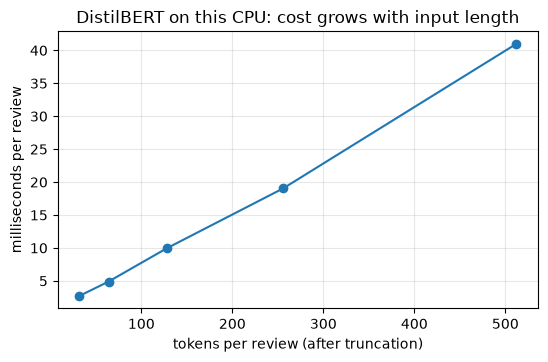

In [10]:
plt.figure(figsize=(6.2, 3.6))
plt.plot(lengths, [t * 1000 for t in per_review], "o-")
plt.xlabel("tokens per review (after truncation)"); plt.ylabel("milliseconds per review")
plt.title("DistilBERT on this CPU: cost grows with input length"); plt.grid(alpha=0.3); plt.show()

The measured time per review rises in a near-straight line with length: each doubling of the token count roughly doubles the time. That's what the multiplication count predicted for this range, where the linear parts dominate. (Your timings will differ from the ones printed here, since they depend on your processor, but the shape of the curve should be the same.) Two practical consequences follow. Truncating reviews to 256 tokens instead of 512 roughly halves inference cost. And if your inputs are long, context length and compute have to be judged together: a model that can read 32,768 tokens will also charge you for reading them.

> **Key terms**
> - **Context length (context window):** the maximum number of tokens a model can take as input at once.
> - **bfloat16 (BF16):** a 16-bit number format, 2 bytes per number, widely used for storing and running large models.
> - **Weight memory:** the memory needed just to hold a model's parameters: parameters × bytes per parameter.
> - **Truncation:** cutting an input down to a maximum number of tokens.

> **Common mistake:** choosing a model by parameter count alone. Two models with similar parameter counts can differ in storage format (float32 or bfloat16), context length and speed. Check the file sizes, the number types and the context length too.

> **Check yourself 2.** A model has 3 billion parameters stored in bfloat16. Estimate its weight memory. Would you expect it to run on a laptop with 8 GB of RAM?

> **Check yourself 3.** Attention's cost grows with the square of the input length. Why, then, did doubling the length from 256 to 512 tokens only roughly double DistilBERT's time per review?

A model that fits your task and your hardware still has to be good enough. That is what model cards and benchmarks claim to tell you.

## 4. Reading Model Cards, Benchmarks and Limitations Critically

### 4.1 Check the claim on its own terms

A **benchmark** is a fixed, public dataset with an agreed way of scoring, so that different models can be compared on equal terms. SST-2 is one such benchmark, and it is part of a larger collection called **GLUE**. Our SST-2 model's card makes its claim in two places:

In [11]:
card = ModelCard.load(SST2)
print("card text:   ", [l.strip() for l in card.text.splitlines() if "accuracy" in l.lower()])
for result in card.data.to_dict()["model-index"][0]["results"]:
    for m in result["metrics"]:
        if m["type"] == "accuracy":
            print("card metadata:", result["dataset"]["name"], result["dataset"]["split"], f"accuracy {m['value']:.4f}")

card text:    ['This model reaches an accuracy of 91.3 on the dev set (for comparison, Bert bert-base-uncased version reaches an accuracy of 92.7).']
card metadata: glue validation accuracy 0.9106
card metadata: sst2 train accuracy 0.9886


The card's text says "an accuracy of 91.3 on the dev set" (dev set is another name for validation set). Its metadata says 0.9106 on the GLUE validation split. These don't quite agree: 91.3 in the text against 0.9106 in the metadata. Small inconsistencies like this are common, because card text and metadata are often written at different times or from different runs. They are a first hint to verify rather than copy.

Let's verify it ourselves. The SST-2 validation set is small and public:

In [12]:
sst2 = load_dataset("stanfordnlp/sst2", cache_dir="data/sst2",
                    data_files={"validation": "data/validation-*.parquet"})["validation"]
print(sst2)
print(sst2[0])

Dataset({
    features: ['idx', 'sentence', 'label'],
    num_rows: 872
})
{'idx': 0, 'sentence': "it 's a charming and often affecting journey . ", 'label': 1}


The validation set has 872 sentences. Look at the first one: it is lowercase, and there are spaces before the punctuation (`it 's`, `journey .`). Benchmark text has often been preprocessed, and may look quite different from what your users will type. Now we run the model on all 872:

In [13]:
out = classifier(list(sst2["sentence"]), batch_size=32)
pred = np.array([o["label"] == "POSITIVE" for o in out])
sst2_acc = (pred == np.array(sst2["label"]).astype(bool)).mean()
print(f"SST-2 validation, {len(sst2)} sentences: accuracy {sst2_acc:.4f}")

SST-2 validation, 872 sentences: accuracy 0.9106


We get 0.9106, exactly the figure in the card's metadata. So the claim is honest, *for SST-2*. That's the first step of critical reading: confirm that a claim can be reproduced on its own terms. The next step is to ask whether it holds on yours.

### 4.2 Check it on your data

Our data is IMDb, with the fixed split from Note 7.1. The function is copied here so this notebook stands alone, and the fingerprints confirm it gives exactly the same reviews.

In [14]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"})
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [15]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


The fingerprints match Note 7.1's. Now the same model on the 1,000 `val_eval` reviews, truncated to 256 tokens:

In [16]:
val_x, val_y = imdb["val_eval"]
out = classifier(val_x, truncation=True, max_length=256, batch_size=32)   # reviews cut to 256 tokens
imdb_pred = np.array([o["label"] == "POSITIVE" for o in out])
imdb_right = imdb_pred == val_y.astype(bool)
print(f"IMDb val_eval, {len(val_x)} reviews: accuracy {imdb_right.mean():.4f}")

IMDb val_eval, 1000 reviews: accuracy 0.8820


Accuracy drops from 0.9106 on SST-2 to 0.8820 on IMDb validation. Same task (positive or negative), same domain (films), a few points lower. Why? The obvious difference is length:

In [17]:
sst2_tokens = np.array([len(ids) for ids in tokenizer(list(sst2["sentence"]))["input_ids"]])
imdb_tokens = np.array([len(ids) for ids in tokenizer(val_x)["input_ids"]])
print(f"median tokens: SST-2 sentences {np.median(sst2_tokens):.0f} | IMDb reviews {np.median(imdb_tokens):.0f}")
short = imdb_tokens <= 256
print(f"IMDb reviews that fit in 256 tokens:  {short.sum():>4} | accuracy {imdb_right[short].mean():.4f}")
print(f"IMDb reviews cut off at 256 tokens:   {(~short).sum():>4} | accuracy {imdb_right[~short].mean():.4f}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (756 > 512). Running this sequence through the model will result in indexing errors


median tokens: SST-2 sentences 24 | IMDb reviews 214
IMDb reviews that fit in 256 tokens:   601 | accuracy 0.9068
IMDb reviews cut off at 256 tokens:    399 | accuracy 0.8446


The median SST-2 sentence is 24 tokens long; the median IMDb review is 214. The model was fine-tuned on single sentences and is now reading whole reviews, often with mixed opinions: a reviewer may praise the acting and still hate the film. On the 601 reviews that fit within 256 tokens, accuracy is 0.9068, close to the card's figure. On the 399 that were cut off, it is 0.8446.

Be careful about what this does and doesn't show. It's tempting to say "truncation costs about six points", but the two groups differ in more than truncation: long reviews may also be more nuanced, more sarcastic or simply harder. This comparison shows that the model does worse on long reviews; it doesn't separate *why*. Note 7.7 measures the effect of the truncation length directly, by running the same reviews at different lengths.

### 4.3 What the model has seen: contamination

There's one more question to ask of any benchmark number: could the model have seen the test data during training? If so, its score measures memory, not ability. This is called **contamination**, and it can happen at either training stage.

In [18]:
print("DistilBERT base was pretrained on:", ModelCard.load("distilbert/distilbert-base-uncased").data.get("datasets"))
print("this checkpoint was fine-tuned on:", card.data.get("datasets"))

DistilBERT base was pretrained on: ['bookcorpus', 'wikipedia']
this checkpoint was fine-tuned on: ['sst2', 'glue']


DistilBERT was pretrained on `bookcorpus` (a collection of books) and `wikipedia`, so IMDb reviews are unlikely to be in its pretraining data, and it was fine-tuned on SST-2's training split, not on its validation split. For this model, both our measurements are clean. But the question needs asking every time:
- Models pretrained on large web crawls may have read IMDb pages, and popular benchmarks themselves often end up in crawled data. A suspiciously high score on a famous dataset is a warning sign.
- Models *fine-tuned* on a dataset will score well on any split they were trained on. If you carve your validation set from IMDb's training half, as we did, a model fine-tuned on IMDb's training half has seen it. Note 7.7 meets exactly this case.

Read the card's training-data section, and if it doesn't say what the model was trained on, treat its benchmark scores with suspicion.

> 🖼 *IMAGE 7.3.2 — Three Readings of One Model.* Three side-by-side vertical bars on a white background, each with its value printed on top, sharing a y-axis labelled "accuracy" from 0.80 to 0.95. Bar 1, grey, labelled "card's claim (SST-2 validation)": 0.9106. Bar 2, blue, labelled "our run, SST-2 validation (872 sentences, median 24 tokens)": 0.9106, with a green tick and the note "claim reproduced". Bar 3, split into two blue sub-bars labelled "our run, IMDb validation (1,000 reviews, median 214 tokens)": left sub-bar "fit in 256 tokens (601)" at 0.9068, right sub-bar "cut off at 256 tokens (399)" at 0.8446, with an overall marker line at 0.8820. Under the chart, a caption box: "Same task, same domain, different text length: verify the claim, then measure on your data." Takeaway: a benchmark score is true for its benchmark; your data decides what you will actually get.

> **Key terms**
> - **Benchmark:** a fixed public dataset and scoring rule used to compare models.
> - **GLUE:** a widely used collection of English language-understanding benchmarks, including SST-2.
> - **Dev set:** another name for a validation set.
> - **Domain shift (distribution shift):** a difference between the data a model was trained or evaluated on and the data it meets in use.
> - **Contamination:** test or benchmark data appearing in a model's training data, which inflates its scores.

> **Common mistake:** treating a lower score on your data as a sign that you made a mistake. A drop from a card's benchmark to your data is normal; it measures the distance between the two datasets. Verify your pipeline on the benchmark itself, as we did, and then believe your own number.

> **Check yourself 4.** The card's text says 91.3 and its metadata says 0.9106. You measured 0.9106 on SST-2 and 0.8820 on IMDb. Which number belongs in a report about using this model for IMDb reviews, and why?

> **Check yourself 5.** Reviews cut off at 256 tokens scored 0.8446, against 0.9068 for reviews that fit. A colleague concludes that using 512 tokens would raise the cut-off group's accuracy to about 0.9068. What's wrong with that reasoning?

So far every model has run on our own computer. The last filter is where the model should run at all.

## 5. Hosted APIs vs. Local Models

There are two ways to use a pretrained model:
- **Locally:** you download the weights and run them on hardware you control, a laptop, a server or a cloud machine you rent. Everything in this module so far has been local.
- **Through a hosted API:** someone else runs the model on their servers. Your code sends the input over the internet and receives the output. Hugging Face, the major AI labs and cloud providers all offer this. An **API** (application programming interface) is simply a defined way for one program to ask another for something.

A hosted call looks like this. The listing is shown but not run, because it needs an account and an **access token**, a secret key that identifies you:

```python
from huggingface_hub import InferenceClient

client = InferenceClient(token="hf_...")        # your access token, from your Hugging Face account settings
result = client.text_classification(
    "The soundtrack alone is worth the price of the ticket.",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
)
print(result)                                   # labels and scores, computed on a remote server
```

Which models are available this way, from which providers and at what price changes often, so check the provider's current documentation. The trade-offs, though, are stable:

| Question | Local model | Hosted API |
|---|---|---|
| Setup | Download weights, install libraries, provide hardware | An account, a token and a few lines of code |
| Which models | Any model whose weights you can download | Whatever the provider offers, including models too big to run yourself |
| Cost | Hardware and electricity, roughly fixed | Pay per request or per token, growing with use |
| Speed | No network delay; limited by your hardware | Network round trip on every call; powerful hardware behind it |
| Privacy | Data never leaves your machine | Data is sent to the provider; check their terms |
| Versioning | You pin the exact weights (Note 7.1, Section 7) | The provider may update or retire a model |
| Availability | Works offline; you handle failures | Depends on the provider's uptime and rate limits |

Neither is better in general. A prototype, or a feature that needs a model far bigger than your hardware, often starts on a hosted API. A product with steady high volume, strict privacy rules or a need for exactly reproducible behaviour often ends up local. Many teams use both: a hosted model to explore, and a local model once they know what they need. Note 7.6 returns to this choice with measured costs.

> **Key terms**
> - **Hosted API:** a service that runs a model on the provider's servers and returns results to your code over the internet.
> - **Access token:** a secret key that identifies you to a service; keep it out of notebooks and code you share.
> - **Rate limit:** a cap on how many requests a service accepts from you in a given time.

> **Common mistake:** pasting an access token directly into a notebook and then sharing the notebook. Anyone who reads it can use your account. Store tokens in an environment variable, or log in once with `hf auth login`, and keep them out of your code.

> **Check yourself 6.** A hospital wants to classify doctors' notes by urgency. A hosted API offers a model that scores slightly better than the best local one. List two questions you would need answered before choosing the hosted option.

## Putting It All Together

Let's reassemble the selection method.

**Start from the problem, not the model.** Five questions (task, inputs, hardware and speed, quality on whose data, deployment and licence) filter the Hub's huge catalogue down to a shortlist.

**The task** maps to a pipeline tag: classification, question answering, summarisation, generation, embeddings, image classification or zero-shot image classification. Models of the same architecture family can serve different tasks with different heads. We ran three: the classifier, a generator that fell into a loop under greedy decoding, and an embedding model that rated two film sentences with no words in common at 0.734 similarity.

**Size and context** can be checked before downloading. Safetensors headers gave stored-number counts from 22,713,728 to 7,615,616,512, and parameters × bytes turned them into memory: Qwen2.5-7B needs 15.23 GB in a 16-bit format, too much for a typical laptop. Context lengths ranged from 512 to 131,072 tokens. For a 512-token encoder, attention is only 10.0% of the multiplications, so cost grows roughly in proportion to length, as our timings confirmed. Beyond 4608 tokens, attention's quadratic cost dominates.

**Quality claims need two checks.** First, reproduce the claim on its own terms: our run on SST-2 validation gave 0.9106, matching the card's metadata (though not its text, which says 91.3). Then measure on your data: on IMDb validation the same model scored 0.8820, with 0.9068 on reviews that fit in 256 tokens and 0.8446 on those that didn't. And always ask what the model saw during training, because contamination inflates scores.

**Where it runs** is the final choice: local models give control, privacy and fixed costs; hosted APIs give convenience and access to bigger models, at a per-use cost and with your data leaving your hands.

| Check | How | Example from this note |
|---|---|---|
| Task | pipeline tag on the Hub | `sentence-similarity` for semantic search |
| Memory | safetensors header × bytes per number | Qwen2.5-7B: 15.23 GB in 16-bit |
| Input limit | `max_position_embeddings` in the config | DistilBERT 512, Qwen2.5-7B 131,072 |
| Claim reproduced? | run on the card's own benchmark | SST-2 validation: 0.9106 = card metadata |
| Holds on your data? | run on your validation set | IMDb val_eval: 0.8820 |
| Contamination? | card's training-data section | pretrained on `bookcorpus`, `wikipedia` |

> 🖼 *IMAGE 7.3.3 — The Model-Selection Checklist.* A vertical checklist card on a white background titled "Before you choose a model". Six rows, each with a check-box, an icon and a short measured example in grey: "Task → pipeline tag (sentence-similarity for search)", "Fits in memory? → header × bytes (7B in 16-bit = 15.23 GB)", "Reads inputs this long? → context length (512 vs 131,072)", "Claim reproduces? → run the card's benchmark (0.9106 ✓)", "Holds on my data? → my validation set (0.8820)", "Seen my data? → training-data section (contamination)". At the bottom, two small boxes side by side: "Local: control, privacy, fixed cost" and "Hosted: convenience, bigger models, per-use cost". Takeaway: each check takes minutes and prevents a wrong choice that could cost days.

## Summary

- Choose models by describing the problem first: **task, inputs, hardware and speed, quality on your data, deployment and licence**.
- Each Hub model has a **pipeline tag** naming its task. Common tasks include text classification, question answering, summarisation, text generation, sentence similarity, image classification and zero-shot image classification.
- Greedy text generation can loop ("It's a very good movie" twice in 20 tokens); sentence embeddings compare meaning, not words (0.734 for two film sentences with no shared words).
- **Safetensors headers** reveal a model's size without downloading it; **parameters × bytes per number** estimates weight memory. Qwen2.5-7B needs 30.46 GB in float32 or 15.23 GB in 16 bits.
- **Context length** ranged from 512 tokens (the BERT family) to 131,072 (Qwen2.5-7B).
- At encoder-sized inputs, linear layers dominate compute: attention is 10.0% of the multiplications at 512 tokens and equals the rest only at 4608. DistilBERT's measured time grew roughly in proportion to length.
- **Verify a card's claim on its own benchmark,** then measure on your data. The SST-2 model scored 0.9106 on SST-2 validation (matching its metadata) but 0.8820 on IMDb validation: 0.9068 on reviews that fit in 256 tokens, 0.8446 on those cut off.
- Ask what a model was trained on: **contamination** inflates scores.
- **Hosted APIs** offer convenience and bigger models, with per-use costs and data leaving your control; **local models** offer privacy, fixed costs and pinned versions.

## Glossary

| Term | Meaning |
|---|---|
| Pipeline tag | The Hub's label for the task a model performs, also used as the `pipeline` task name. |
| Text classification | Assigning one label to a whole text. |
| Question answering | Finding the span of a passage that answers a question. |
| Summarisation | Producing a shorter version of a long text. |
| Text generation | Continuing a prompt with new text. |
| Sentence embedding | One vector for a whole sentence, placing similar meanings close together. |
| Zero-shot image classification | Classifying an image into labels given as words at run time. |
| Greedy decoding | Generating by always choosing the most likely next token. |
| Safetensors header | The start of a safetensors file, listing each tensor's name, shape and number type. |
| bfloat16 (BF16) | A 16-bit number format, 2 bytes per number. |
| Weight memory | Memory needed to hold a model's parameters: parameters × bytes per parameter. |
| Context length | The maximum number of tokens a model accepts at once. |
| Truncation | Cutting an input down to a maximum number of tokens. |
| Benchmark | A fixed public dataset and scoring rule for comparing models. |
| GLUE | A collection of English language-understanding benchmarks, including SST-2. |
| Dev set | Another name for a validation set. |
| Domain shift | A difference between the data a model was built on and the data it meets in use. |
| Contamination | Evaluation data appearing in a model's training data, inflating its scores. |
| Hosted API | A service that runs a model remotely and returns results over the internet. |
| Access token | A secret key that identifies you to a service. |
| Rate limit | A cap on how many requests a service accepts in a given time. |

## Answers to Check Yourself

**1.** `sentence-similarity` (or `feature-extraction`): embed every past ticket once, embed the new ticket, and return the past tickets whose vectors are closest. Text classification needs a fixed set of labels decided in advance, but "the same problem as this ticket" isn't a fixed label: there could be thousands of distinct problems, and new ones appear all the time.

**2.** 3 billion × 2 bytes = about 6 GB for the weights alone. On an 8 GB laptop that leaves very little room for the operating system, other programs and the computation itself, so it would probably fail or be extremely slow. A smaller model, or a more compressed format (Note 7.6), would be needed.

**3.** Because at these lengths most of the work is in the linear layers, whose cost grows only in proportion to length. At 512 tokens, attention is just 10.0% of DistilBERT's multiplications. Doubling the length doubles the linear work and quadruples the small attention part, so the total roughly doubles. The quadratic part dominates only for much longer inputs, beyond about 4608 tokens for this layer size.

**4.** 0.8820, the number measured on IMDb validation, because it is measured on the kind of data the model will actually see. The SST-2 figures describe a different dataset. The 0.9106 we reproduced is still useful: it shows our pipeline runs the model correctly. (Report the final figure on the test set, once settings have been chosen on validation.)

**5.** The two groups differ in more than truncation. Long reviews may be harder in their own right: more mixed opinions, more plot summary, more sarcasm. Giving the model 512 tokens might help, but there's no reason to expect it to reach the short-review accuracy, and some reviews are longer than 512 anyway. The way to find out is an experiment that changes only the truncation length on the same reviews, which Note 7.7 does.

**6.** For example: Can patient data legally be sent to this provider at all, and what do their terms say about storing or using it? Is the provider's model version pinned, or could it change without warning? What does it cost at the hospital's volume, and is the network delay acceptable for urgent cases? What happens to the service if the provider has an outage or reaches a rate limit?